# Quick start: ResegmentArticle

Re-segment a Delpher article into paragraphs (and optionally split merged articles).

**Scope:** regular articles only, not advertisements. Article splitting works best on older newspapers (long columns, simple layout, clear headers). Paragraph splitting works well wherever paragraphs start with an indentation. See the README for details.

**Requirements:** `pip install -e ..` (from this folder), `jupyter`, `python-dotenv`, and a `.env` file with `DELPHER_API_KEY=...` (needed to download mpeg21 metadata for copyrighted newspapers; files already in the cache folders are used offline).

If you don't have an Delpher API key, you could get the article zone information through the SRU API. See below.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import dotenv
import pandas as pd

from segment_article import RedefineArticle, plot_blocks, fetch_image

# You need a delpher API key to obtain mpeg21 metadata for non-public domain works
dotenv.load_dotenv()
DELPHER_API_KEY = os.getenv("DELPHER_API_KEY")

pd.set_option("display.max_colwidth", 100)

In [16]:
def article_url(article_id):
    """Generate the URL for a given article ID."""
    return f"https://resolver.kb.nl/resolve?urn={article_id}"

## 1. Paragraphs of an article

`process_article()` returns one row per paragraph. The article spans two pages here; the text of a paragraph continuing over the page break is kept in the correct order.

In [60]:
article_id = "ddd:000022499:mpeg21:a0013" # Older article
# article_id = "KBPERS01:003289013:mpeg21:a00376" # More recent article
print(article_url(article_id))

ra = RedefineArticle(
    article_id=article_id,
    delpher_api_key=DELPHER_API_KEY,
    alto_cache_dir="alto_cache",      # downloaded ALTO is stored here
    mpeg21_cache_dir="mpeg21_cache",  # paper metadata is stored here
    ignore_blocks=True,               # segment on line spacing across the page
    article_split_threshold=1.3,      # lower = more article splits
    keep_styles=False,                # faster, styles are not needed here
)

df = ra.process_article()
df.head()

https://resolver.kb.nl/resolve?urn=ddd:000022499:mpeg21:a0013


,paragraph_id,text,line_id,page_id,article_id
0,P001,KOLONIEN.,[P3_TL00157],ddd:000022499:mpeg21:p003,A001
1,P002,{L*er Overland tnail),[P3_TL00158],ddd:000022499:mpeg21:p003,A001
2,P003,"BATAVIA, IA July.",[P3_TL00159],ddd:000022499:mpeg21:p003,A002
3,P004,Aan het algemeen overzigt van den Java-Bode wordt het volgende ontleend :,"[P3_TL00160, P3_TL00161]",ddd:000022499:mpeg21:p003,A002
4,P005,De Gouverneur-Generaal is met zijne familie van zijne inspectiereis alhier weder in gezondheid g...,"[P3_TL00162, P3_TL00163]",ddd:000022499:mpeg21:p003,A002


Convert splitted paragraphs for a newly created article split into text, and the XML format used to store the OCR data in the newspaper dataset:

In [77]:
import textwrap

new_article_id = df["article_id"].iloc[2]
new_article_paragraphs = df.loc[df["article_id"] == new_article_id]

new_text = ra.paragraphs_to_text(new_article_paragraphs)

print(textwrap.fill(new_text[:800], width=80, replace_whitespace=False))

Binnenland.

's GRAVENHAGE,11 Mei.

De heer Mr. J. W. Foest. commissaris van
politie bij hel hoofdbureau te Amsterdam , is door Z. M. den Koning benoeiud tot
ridder tier orde van dc Eikenkroon.

Aan J. van Groningen, is op zijn verzoek,
met ingang van den 1 Julij e. k. , eervol ontslag verleend als bode en conciërge
bij de administratie voor de Zaken der Hervormde en andere Eerediensten.

De
heer G. Kohier, Nederlandsch consul te Sydney voor Nieuw-Zuid-Wales , is benoemd
tot consul-generaal.

— De heer J. A. Baesjou is benoemd tot Nederlandsebeu
consul te Albany voor West-Australië.

H. M. de Koningin heeft heden morgen ten
5% ure.de resideutie verlaten en zich naar Stuttgardt begeven. H. M. wordt
vergezeld door de baronesse van Pabst van Bingerden , den kamerheer graaf
Schimmel pen uin ck


In [76]:
new_article_xml = ra.paragraphs_to_xml(new_article_paragraphs)
print(textwrap.fill(new_article_xml[:800], width=80, replace_whitespace=False))

<?xml version="1.0" encoding="UTF-8"?>
<text>
<p>BATAVIA, IA July.</p>
<p>Aan
het algemeen overzigt van den Java-Bode wordt het volgende ontleend :</p>
<p>De
Gouverneur-Generaal is met zijne familie van zijne inspectiereis alhier weder in
gezondheid gearriveerd.</p>
<p>In den politieken toestand is geene verandering
te bespeuren. De expeditie naar Nias is meteen guustigen afloop bekroond
geworden , en de daarheen vertrokken troepen waren reeds den 26 Junij in goeden
welstand te Padang teruggekeerd en werden aan de landingsplaats door zeer vele
belangstellenden met vreugde begroet. Van de Zuid- en Ooster-afdeeling van
Borneo is nog niets bijzonders bekend. De gezondheidstoestand laat, behalve op
de Westkust van Sumatra , waar zich zeer vele gevallen van pokziekten voordoen ,
niets te wensch


## 2. Check the result visually

The per-page `SegmentPage` objects hold the line-level results. Plot them on the page scan, coloured by paragraph (or `article_id`).

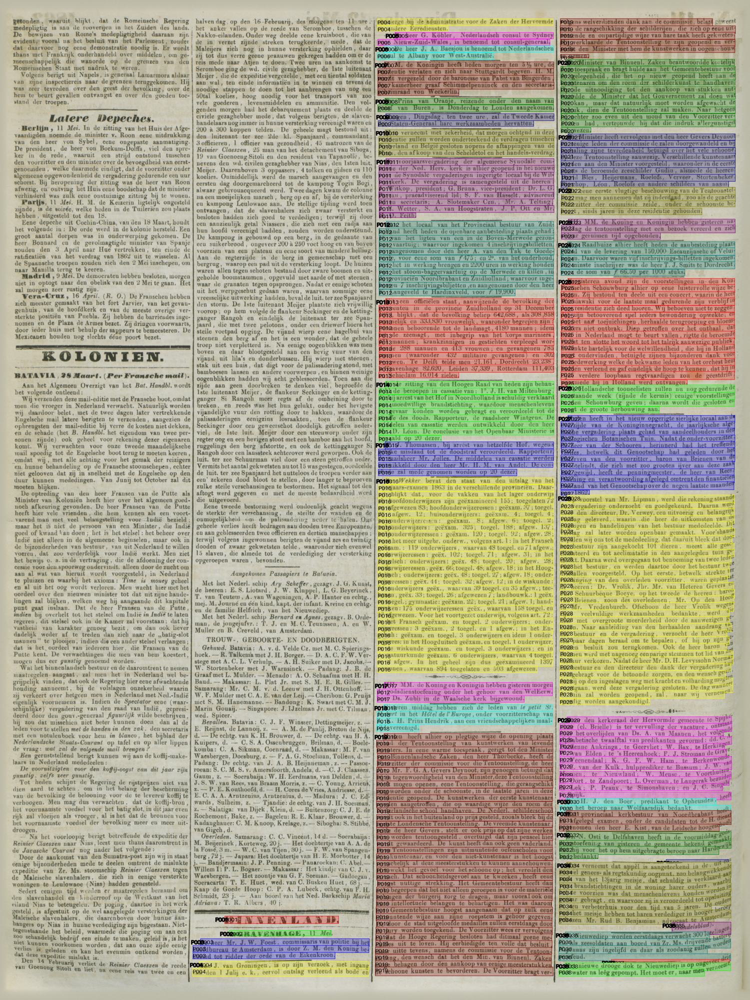

In [79]:
# Index of the page to visualize, as some articles may span multiple pages
page_idx = 0
# Get the page ID and the corresponding segment page object
page_id = list(ra.page_block_filter.keys())[page_idx]
sg = ra._segment_page_objects[page_idx]

img = fetch_image(page_id, image_cache="image_cache")

plot_blocks(
    img,
    sg.df,
    color_column="paragraph_id",  # try "article_id" to check the article splits
    id_column="paragraph_id",
    add_fill=True,
    add_id=True,
    add_color_id=True,
    return_thumbnail=True
)

Line level data (this is where the split decisions are visible):

In [78]:
sg.df[["id", "block_id", "text", "is_article_start", "article_id", "is_paragraph_start", "paragraph_id"]].head(30)

,id,block_id,text,is_article_start,article_id,is_paragraph_start,paragraph_id
0,P3_TL00157,P3_TB00015,KOLONIEN.,True,A001,True,P001
1,P3_TL00158,P3_TB00016,{L*er Overland tnail),False,A001,True,P002
2,P3_TL00159,P3_TB00017,"BATAVIA, IA July.",True,A002,True,P003
3,P3_TL00160,P3_TB00017,Aan het algemeen overzigt van den Java-Bode wordt het,False,A002,True,P004
4,P3_TL00161,P3_TB00017,volgende ontleend :,False,A002,False,P004
5,P3_TL00162,P3_TB00018,De Gouverneur-Generaal is met zijne familie van zijne,False,A002,True,P005
6,P3_TL00163,P3_TB00018,inspectiereis alhier weder in gezondheid gearriveerd.,False,A002,False,P005
7,P3_TL00164,P3_TB00018,In den politieken toestand is geene verandering te be,False,A002,True,P006
8,P3_TL00165,P3_TB00018,speuren. De expeditie naar Nias is meteen guustigen afloop,False,A002,False,P006
9,P3_TL00166,P3_TB00018,"bekroond geworden , en de daarheen vertrokken troepen",False,A002,False,P006


## 3. Tune article splitting

`article_split_threshold` is the main knob. Compare thresholds on an article from a newer newspaper: a higher value removes false splits but may also miss real ones.

In [70]:
article_id = "ddd:000022389:mpeg21:a0008"
print(article_url(article_id))


for threshold in (1.3, 1.7, 2.5):
    ra = RedefineArticle(
        article_id=article_id,
        delpher_api_key=DELPHER_API_KEY,
        alto_cache_dir="alto_cache",
        mpeg21_cache_dir="mpeg21_cache",
        ignore_blocks=True,
        article_split_threshold=threshold,
        keep_styles=False,
    )
    df = ra.process_article()
    print(f"threshold={threshold}: {df['article_id'].nunique()} article(s), {len(df)} paragraph(s)")

https://resolver.kb.nl/resolve?urn=ddd:000022389:mpeg21:a0008
threshold=1.3: 11 article(s), 57 paragraph(s)
threshold=1.7: 10 article(s), 57 paragraph(s)
threshold=2.5: 7 article(s), 61 paragraph(s)


## 4. Keyword filtering

With `keywords`, only the articles containing a keyword are kept (plus up to `max_paragraph_gap` paragraphs between hits).

In [19]:
article_id = "ddd:000022389:mpeg21:a0007"

ra = RedefineArticle(
    article_id=article_id,
    keywords=["nias"],  # replace with a word that occurs in the article
    max_paragraph_gap=5,
    delpher_api_key=DELPHER_API_KEY,
    alto_cache_dir="alto_cache",
    mpeg21_cache_dir="mpeg21_cache",
    ignore_blocks=True,
    keep_styles=False,
)
ra.process_article()

,text,line_id,page_id,article_id
0,Aan het Algemeen Overzigt van het Bat. Handbl. wordt het volgende ontleend:,"[P2_TL00049, P2_TL00050]",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
1,"Wij verzenden deze mail-editie met de Fransche boot,omdat men die vroeger in Nederland verwacht....","[P2_TL00051, P2_TL00052, P2_TL00053, P2_TL00054, P2_TL00055, P2_TL00056, P2_TL00057, P2_TL00058,...",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
2,De optreding vau deu heer Fransen van tle Putte als Minister van Koloniën heeft hier over het al...,"[P2_TL00065, P2_TL00066, P2_TL00067, P2_TL00068, P2_TL00069, P2_TL00070, P2_TL00071, P2_TL00072,...",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
3,"""Wat het binnenlandsch bestuur en de daaromtrent te nemen maatregelen aangaat, zal uien het in N...","[P2_TL00091, P2_TL00092, P2_TL00093, P2_TL00094, P2_TL00095, P2_TL00096, P2_TL00097, P2_TL00098,...",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
4,Een geruststellend berigt kunnen wij aan dc koflij-makelaars in Nederland inededeelen :,"[P2_TL00104, P2_TL00105]",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
5,"De vooruitzigten voor den koffij-oogst van dit jaar zijn gunstig, zelfs zeer gunstig.","[P2_TL00106, P2_TL00107]",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
6,Tot hedeu schijnt de Regering de rijstprijzen uiet van riten aard te achten . om in liet belang ...,"[P2_TL00108, P2_TL00109, P2_TL00110, P2_TL00111, P2_TL00112, P2_TL00113, P2_TL00114, P2_TL00115]",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
7,"Na het voorloopig berigt betreffende de expeditie der Reinier Claeszen naar Nias, leest men than...","[P2_TL00116, P2_TL00117, P2_TL00118]",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
8,Door dc aankomst van den Sumatra-post zijn wij in staat eenige bijzonderheden mede te deelen omt...,"[P2_TL00119, P2_TL00120, P2_TL00121, P2_TL00122, P2_TL00123, P2_TL00124, P2_TL00125, P2_TL00126,...",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007
9,"n i_3tpeditie misl»kt is. van Goeno^sSj^f t ÏZ™. C,ae""en de leede","[P2_TL00134, P2_TL00135]",ddd:000022389:mpeg21:p002,ddd:000022389:mpeg21:a0007


## 5. Supplying your own zones

Instead of the mpeg21 file for getting the zones/blocks, you can pass image-coordinate zones that can be obtained through the SRU API. Each zone dictionary contains the coordinates for one block (they match exactly with the blocks in the ALTO file). 

If you pass the zones like this, it saves a request to get the mpeg21 file for a specific paper. If you collect the zones while harvesting the search results, this can reduce the processing time a lot, as these metadata files can be quite large.

With `add_zoning=True` the new zones for the re-segmented article can be exported in the same format. This is mainly for cutting out article pieces from the scan image. You cannot provide this back in as `zoning` argument, as these zones don't line up with the original blocks.

In [38]:
# Example of using RedefineArticle to get updated article zones
article_id = "ddd:000022499:mpeg21:a0013"
print(article_url(article_id))

ra = RedefineArticle(
    article_id=article_id,
    add_zoning=True,
    delpher_api_key=DELPHER_API_KEY,
    alto_cache_dir="alto_cache",
    mpeg21_cache_dir="mpeg21_cache",
    ignore_blocks=True,
    keep_styles=False,
)
ra.get_page_paragraphs()
zones = ra.zoning_to_dict()  # list of {'x', 'y', 'w', 'h', 'image'}
zones[:3]

https://resolver.kb.nl/resolve?urn=ddd:000022499:mpeg21:a0013


[{'x': 1165,
  'y': 1642,
  'w': 643,
  'h': 56,
  'image': 'DDD_000022499_003_access.jp2'},
 {'x': 1256,
  'y': 1722,
  'w': 444,
  'h': 36,
  'image': 'DDD_000022499_003_access.jp2'},
 {'x': 1023,
  'y': 1787,
  'w': 928,
  'h': 113,
  'image': 'DDD_000022499_003_access.jp2'}]

### Get the zones from the SRU

In this example we search for one article to get its zones, but it would of course be more efficient if you collected the zones while you harvest your search results.

In [42]:
# Get article zones from the SRU service (as example)
from lxml import etree
import requests
import ast
from pprint import pprint

article_id = "ddd:000022499:mpeg21:a0013"
print(article_url(article_id))

# Search for the specific article; 
sru_params = {
    'operation': 'searchRetrieve',
    'version': '1.2',
    'query': f'metadataKey = "{article_id}"',
    'maximumRecords': 1,
    'x-collection': 'DDD_artikel',
    'recordSchema': 'ddd',
    'x-fields': 'zones'
}

sru_url = 'https://jsru.kb.nl/sru/sru'
with requests.get(sru_url, params=sru_params) as response:
    xml_content = response.content
    root = etree.fromstring(xml_content)

zones_obj = root.find(".//zones", root.nsmap)
zones = ast.literal_eval(zones_obj.text)
pprint(zones)

https://resolver.kb.nl/resolve?urn=ddd:000022499:mpeg21:a0013
[{'h': 59,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 643,
  'x': 1165,
  'y': 1641},
 {'h': 36,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 444,
  'x': 1256,
  'y': 1722},
 {'h': 113,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 930,
  'x': 1022,
  'y': 1787},
 {'h': 1604,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 932,
  'x': 1018,
  'y': 1902},
 {'h': 213,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 929,
  'x': 1018,
  'y': 3508},
 {'h': 530,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 932,
  'x': 1018,
  'y': 3722},
 {'h': 496,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 931,
  'x': 1020,
  'y': 4253},
 {'h': 348,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 932,
  'x': 1023,
  'y': 4752},
 {'h': 70,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 924,
  'x': 1030,
  'y': 5106},
 {'h': 3005,
  'image': 'DDD_000022499_003_access.jp2',
  'w': 933,
  'x': 1978,
  'y': 97},
 

### Use zones as input

In [ ]:
# Re-run using only these zones as input
ra_zones = RedefineArticle(
    article_id=article_id,
    zones=zones,
    delpher_api_key=DELPHER_API_KEY,
    alto_cache_dir="alto_cache",
    ignore_blocks=True,
    keep_styles=False,
)
ra_zones.process_article().head()

,paragraph_id,text,line_id,page_id,article_id
0,P001,KOLONIEN.,[P3_TL00157],ddd:000022499:mpeg21:p003,A001
1,P002,{L*er Overland tnail),[P3_TL00158],ddd:000022499:mpeg21:p003,A001
2,P003,"BATAVIA, IA July.",[P3_TL00159],ddd:000022499:mpeg21:p003,A002
3,P004,Aan het algemeen overzigt van den Java-Bode wordt het volgende ontleend :,"[P3_TL00160, P3_TL00161]",ddd:000022499:mpeg21:p003,A002
4,P005,De Gouverneur-Generaal is met zijne familie van zijne inspectiereis alhier weder in gezondheid g...,"[P3_TL00162, P3_TL00163]",ddd:000022499:mpeg21:p003,A002


### Difference in processing time with and without providing zones

In [ ]:
%%timeit

# With provided zones
ra_zones = RedefineArticle(
    article_id=article_id,
    zones=zones,
    delpher_api_key=DELPHER_API_KEY,
    alto_cache_dir="alto_cache",
)

df = ra_zones.process_article()

282 ms ± 7.84 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
%%timeit

# Without provided zones (gets the mpeg21 XML to get the zoning)
ra_zones = RedefineArticle(
    article_id=article_id,
    delpher_api_key=DELPHER_API_KEY,
    alto_cache_dir="alto_cache",
)

df = ra_zones.process_article()

421 ms ± 7.63 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
